# Prototipo de sistema de reconocimiento de objetos en imágenes. Caso particular: detección de armas.

Autor: Jhon Fredy Montenegro

**Requisito:** entorno de ejecución con GPU (Colab → *Entorno de ejecución → Cambiar tipo de entorno → GPU T4*).


## 0. Configuración

Todos los parámetros ajustables están en esta celda. Si el entorno se reinicia, vuelva a ejecutarla antes de cualquier otra.

In [1]:
import os, random
from pathlib import Path

SEED = 42
MODEL_NAME = "yolo11s.pt"   # yolo11n.pt = más rápido | yolo11s.pt = balance | yolo11m.pt = más preciso y más lento
IMG_SIZE = 640
EPOCHS = 60
BATCH = 16
PATIENCE = 15               # parada temprana si val no mejora en N épocas

INCLUDE_KNIVES = True       # True: detecta pistolas y cuchillos | False: solo pistolas
NEG_RATIO = 0.20            # nº de imágenes sin arma = NEG_RATIO * nº de imágenes con arma
MAX_SIDE = 1280             # las imágenes más grandes se reducen (ahorra disco y tiempo)
SPLIT = (0.8, 0.1, 0.1)     # train, val, test

CONF_THRESHOLD = 0.40       # valor inicial; la sección 4 lo recalibra con los datos de test

USE_DRIVE = False            # guarda los pesos en Google Drive para no perderlos al cerrar la sesión

REPO_DIR = Path("/content/OD-WeaponDetection")
DATASET_DIR = Path("/content/dataset")
DATA_YAML = DATASET_DIR / "data.yaml"
RUNS_DIR = Path("/content/runs")
RUN_NAME = "armas_" + MODEL_NAME.split(".")[0]
DRIVE_DIR = Path("/content/drive/MyDrive/deteccion_armas")

CLASS_NAMES = ["pistola", "cuchillo"] if INCLUDE_KNIVES else ["pistola"]

random.seed(SEED)
print("Clases:", CLASS_NAMES)

Clases: ['pistola', 'cuchillo']


In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "ATENCIÓN: no hay GPU. Active la GPU en el entorno de ejecución."
!pip install -q "ultralytics>=8.3.0"

import ultralytics
ultralytics.checks()

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [3]:
# (Opcional) Montar Google Drive para conservar los pesos entrenados
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR.mkdir(parents=True, exist_ok=True)
        print("Drive listo en", DRIVE_DIR)
    except Exception as e:
        USE_DRIVE = False
        print("No se pudo montar Drive, se continúa sin él:", e)

## 1. Obtención de las imágenes

Se descargan del repositorio [ari-dasci/OD-WeaponDetection](https://github.com/ari-dasci/OD-WeaponDetection) (licencia CC BY-SA 4.0) solo las carpetas necesarias:

- `Pistol detection`: 3000 imágenes de pistolas con su anotación XML (cajas reales).
- `Knife_detection`: 1000 imágenes de cuchillos con su anotación XML.
- `Pistol classification`: imágenes de objetos cotidianos (Caltech-101: caras, teléfonos, tijeras, llaves inglesas, etc.). Se usan como **negativos**, excluyendo la carpeta de pistolas (`AAAPistol`) y `cannon`.

Se usa *sparse checkout* para no bajar el repositorio completo (2.3 GB).

In [4]:
if not REPO_DIR.exists():
    !git clone --depth 1 --filter=blob:none --sparse https://github.com/ari-dasci/OD-WeaponDetection.git {REPO_DIR}
    !cd {REPO_DIR} && git sparse-checkout set "Pistol detection" "Knife_detection" "Pistol classification"
else:
    print("Repositorio ya descargado:", REPO_DIR)

for sub in ["Pistol detection/Weapons", "Pistol detection/xmls",
            "Knife_detection/Images", "Knife_detection/annotations", "Pistol classification"]:
    p = REPO_DIR / sub
    n = sum(1 for f in p.rglob("*") if f.is_file()) if p.exists() else 0
    print(f"{'OK ' if n else 'FALTA'} {sub}: {n} archivos")

Cloning into '/content/OD-WeaponDetection'...
remote: Enumerating objects: 235, done.
remote: Counting objects: 100% (235/235), done.
remote: Compressing objects: 100% (141/141), done.
remote: Total 235 (delta 94), reused 234 (delta 94), pack-reused 0 (from 0)
Receiving objects: 100% (235/235), 1.15 MiB | 16.42 MiB/s, done.
Resolving deltas: 100% (94/94), done.
remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 0), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2/2), 7.01 KiB | 7.01 MiB/s, done.
remote: Enumerating objects: 19303, done.
remote: Counting objects: 100% (19303/19303), done.
remote: Compressing objects: 100% (14250/14250), done.
remote: Total 19303 (delta 5077), reused 19274 (delta 5053), pack-reused 0 (from 0)
Receiving objects: 100% (19303/19303), 985.64 MiB | 31.60 MiB/s, done.
Resolving deltas: 100% (5077/5077), done.
Updating files: 100% (20013/200

## 2. Preparación del dataset en formato YOLO

Pasos:

1. Leer cada XML (Pascal VOC) y emparejarlo con su imagen.
2. Convertir cada caja `xmin, ymin, xmax, ymax` (píxeles) al formato YOLO `clase x_centro y_centro ancho alto` (normalizado 0–1). Las cajas se recortan al borde de la imagen y se descartan las degeneradas.
3. Agregar imágenes negativas (sin arma), repartidas entre todas las categorías de Caltech para que sean variadas.
4. Eliminar duplicados exactos (para que una misma imagen no quede en train y en test).
5. Partir en train/val/test de forma estratificada y reproducible, con nombres de archivo únicos.
6. Escribir `data.yaml`.

In [5]:
import hashlib, math, shutil
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from PIL import Image, ImageOps
from tqdm.auto import tqdm

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
LABEL_MAP = {"pistol": 0, "handgun": 0, "gun": 0, "pistola": 0, "knife": 1, "cuchillo": 1}
NEG_EXCLUDE = {"AAAPistol", "cannon"}
rng = random.Random(SEED)
stats = Counter()


def index_images(folder):
    return {p.stem: p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT}


def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    w = int(float(size.findtext("width", "0") or 0)) if size is not None else 0
    h = int(float(size.findtext("height", "0") or 0)) if size is not None else 0
    objs = []
    for obj in root.findall("object"):
        name = (obj.findtext("name") or "").strip().lower()
        bb = obj.find("bndbox")
        if bb is None:
            continue
        try:
            coords = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        except (TypeError, ValueError):
            stats["caja_ilegible"] += 1
            continue
        objs.append((name, *coords))
    return (w, h), objs


def collect_detection_set(img_dir, xml_dir, source):
    imgs = index_images(img_dir)
    items, missing = [], 0
    for xml in sorted(Path(xml_dir).glob("*.xml")):
        img = imgs.get(xml.stem)
        if img is None:
            missing += 1
            continue
        xml_size, objs = parse_voc(xml)
        items.append({"img": img, "xml_size": xml_size, "objs": objs, "source": source})
    print(f"{source}: {len(items)} imágenes anotadas ({missing} XML sin imagen)")
    return items


positives = collect_detection_set(REPO_DIR / "Pistol detection/Weapons",
                                  REPO_DIR / "Pistol detection/xmls", "pistola")
if INCLUDE_KNIVES:
    positives += collect_detection_set(REPO_DIR / "Knife_detection/Images",
                                       REPO_DIR / "Knife_detection/annotations", "cuchillo")

# Negativos: repartidos en round-robin entre categorías para que haya variedad
cls_root = REPO_DIR / "Pistol classification"
by_cat = {}
for d in sorted(cls_root.iterdir()):
    if d.is_dir() and d.name not in NEG_EXCLUDE:
        files = sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT)
        rng.shuffle(files)
        if files:
            by_cat[d.name] = files
n_neg = int(NEG_RATIO * len(positives))
negatives = []
while len(negatives) < n_neg and any(by_cat.values()):
    for cat in list(by_cat):
        if by_cat[cat] and len(negatives) < n_neg:
            negatives.append({"img": by_cat[cat].pop(), "xml_size": (0, 0), "objs": [], "source": "fondo"})
print(f"fondo: {len(negatives)} imágenes negativas de {len(by_cat)} categorías")

# Eliminar duplicados exactos (mismo contenido de archivo)
all_items, seen = [], set()
for it in positives + negatives:
    h = hashlib.md5(it["img"].read_bytes()).hexdigest()
    if h in seen:
        stats["duplicadas"] += 1
        continue
    seen.add(h)
    all_items.append(it)
print("Duplicados eliminados:", stats["duplicadas"])

# Partición estratificada por origen
by_src = defaultdict(list)
for it in all_items:
    by_src[it["source"]].append(it)
for src, lst in by_src.items():
    rng.shuffle(lst)
    n_tr, n_va = int(len(lst) * SPLIT[0]), int(len(lst) * SPLIT[1])
    for i, it in enumerate(lst):
        it["split"] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")

pistola: 3000 imágenes anotadas (0 XML sin imagen)
cuchillo: 2078 imágenes anotadas (0 XML sin imagen)
fondo: 1015 imágenes negativas de 100 categorías
Duplicados eliminados: 13


In [6]:
def to_yolo_lines(objs, ref_w, ref_h):
    lines = []
    for name, x1, y1, x2, y2 in objs:
        cls = LABEL_MAP.get(name)
        if cls is None:
            stats[f"clase_desconocida:{name}"] += 1
            continue
        if cls >= len(CLASS_NAMES):          # p. ej. cuchillo cuando INCLUDE_KNIVES=False
            continue
        if not all(math.isfinite(v) for v in (x1, y1, x2, y2)):
            stats["caja_invalida"] += 1
            continue
        x1, x2 = sorted((min(max(x1, 0), ref_w), min(max(x2, 0), ref_w)))
        y1, y2 = sorted((min(max(y1, 0), ref_h), min(max(y2, 0), ref_h)))
        if (x2 - x1) < 2 or (y2 - y1) < 2:
            stats["caja_invalida"] += 1
            continue
        lines.append(f"{cls} {(x1 + x2) / 2 / ref_w:.6f} {(y1 + y2) / 2 / ref_h:.6f} "
                     f"{(x2 - x1) / ref_w:.6f} {(y2 - y1) / ref_h:.6f}")
    return lines


def export_item(it, out_img, out_lbl):
    try:
        raw = Image.open(it["img"])
        raw.load()
    except Exception:
        stats["imagen_corrupta"] += 1
        return False
    W, H = raw.size
    xw, xh = it["xml_size"]
    img = raw
    # Si el XML tiene ancho/alto intercambiados, la anotación se hizo sobre la imagen rotada por EXIF
    if xw > 0 and xh > 0 and (xw, xh) == (H, W) and W != H:
        img = ImageOps.exif_transpose(raw)
        stats["rotadas_por_exif"] += 1
    ref_w, ref_h = (xw, xh) if xw > 0 and xh > 0 else img.size

    lines = to_yolo_lines(it["objs"], ref_w, ref_h)
    if it["objs"] and not lines:             # tenía arma pero ninguna caja válida: se descarta
        stats["descartada_sin_cajas_validas"] += 1
        return False

    img = img.convert("RGB")
    if max(img.size) > MAX_SIDE:
        img.thumbnail((MAX_SIDE, MAX_SIDE))  # conserva proporción, las coordenadas normalizadas no cambian
    img.save(out_img, "JPEG", quality=95)    # se guarda sin EXIF para evitar rotaciones inesperadas
    out_lbl.write_text("\n".join(lines) + ("\n" if lines else ""))
    stats["cajas"] += len(lines)
    return True


if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
for s in ("train", "val", "test"):
    (DATASET_DIR / "images" / s).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / s).mkdir(parents=True, exist_ok=True)

summary = Counter()
counters = Counter()
for it in tqdm(all_items, desc="Exportando"):
    counters[it["source"]] += 1
    stem = f"{it['source']}_{counters[it['source']]:05d}"
    ok = export_item(it,
                     DATASET_DIR / "images" / it["split"] / f"{stem}.jpg",
                     DATASET_DIR / "labels" / it["split"] / f"{stem}.txt")
    if ok:
        summary[(it["split"], it["source"])] += 1

DATA_YAML.write_text(
    f"path: {DATASET_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES))
)

import pandas as pd
tabla = pd.Series(summary).unstack(fill_value=0).reindex(["train", "val", "test"])
tabla["total"] = tabla.sum(axis=1)
display(tabla)
print("Estadísticas de conversión:", dict(stats))
print(DATA_YAML.read_text())

Exportando:   0%|          | 0/6080 [00:00<?, ?it/s]

,cuchillo,fondo,pistola,total
train,1662,812,2389,4863
val,207,101,298,606
test,209,102,300,611


Estadísticas de conversión: {'duplicadas': 13, 'cajas': 5604, 'caja_invalida': 1}
path: /content/dataset
train: images/train
val: images/val
test: images/test
names:
  0: pistola
  1: cuchillo



### Verificación visual de las etiquetas

Antes de entrenar se dibujan algunas cajas sobre imágenes de entrenamiento. Si las cajas no rodean el arma, el entrenamiento no sirve (este paso habría detectado el error de la versión anterior).

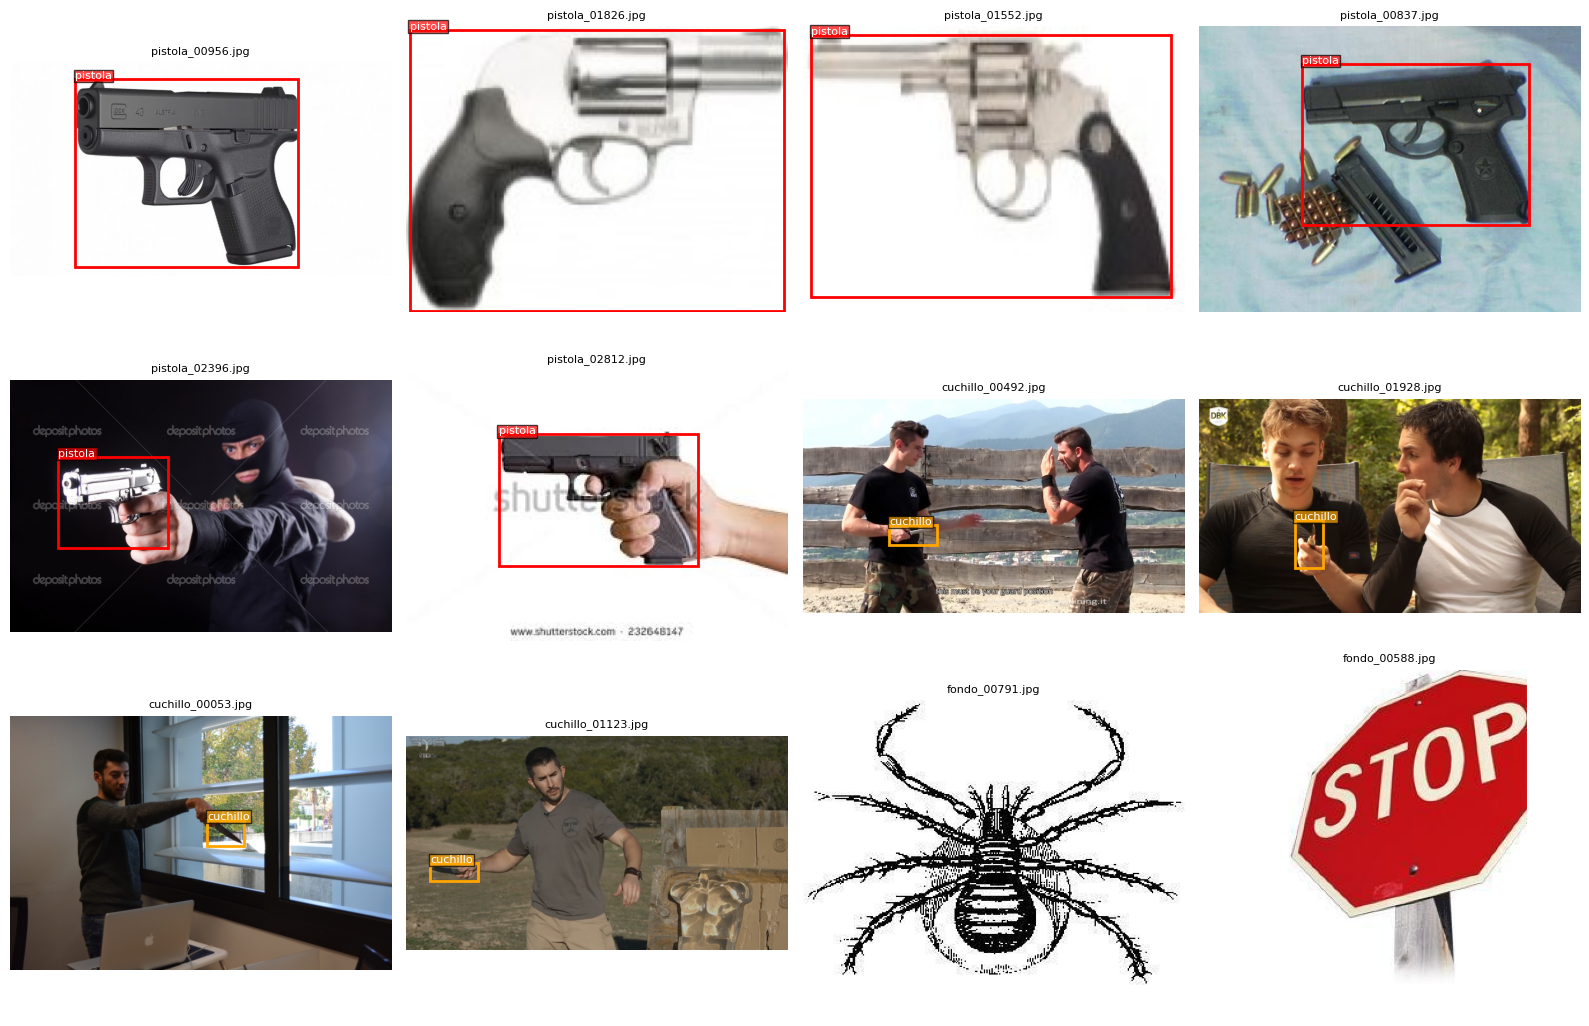

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

COLORS = ["red", "orange", "cyan"]

def show_labeled(img_paths, split, cols=4):
    rows = math.ceil(len(img_paths) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, p in zip(axes.flat, img_paths):
        img = Image.open(p)
        W, H = img.size
        ax.imshow(img)
        lbl = DATASET_DIR / "labels" / split / (p.stem + ".txt")
        for line in lbl.read_text().split("\n"):
            if not line.strip():
                continue
            c, xc, yc, w, h = line.split()
            c, xc, yc, w, h = int(c), float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
            ax.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, fill=False,
                                           color=COLORS[c % len(COLORS)], linewidth=2))
            ax.text(xc - w / 2, yc - h / 2, CLASS_NAMES[c], color="white", fontsize=8,
                    bbox=dict(facecolor=COLORS[c % len(COLORS)], alpha=0.7, pad=1))
        ax.set_title(p.name, fontsize=8)
    plt.tight_layout()
    plt.show()

train_imgs = sorted((DATASET_DIR / "images/train").glob("*.jpg"))
muestra = []
for prefijo, n in [("pistola", 6), ("cuchillo", 4), ("fondo", 2)]:
    grupo = [p for p in train_imgs if p.name.startswith(prefijo)]
    muestra += rng.sample(grupo, min(n, len(grupo)))
show_labeled(muestra, "train")

## 3. Entrenamiento

Se parte de pesos preentrenados en COCO (*transfer learning*). Además de las aumentaciones por defecto de Ultralytics (mosaico, volteo horizontal, escala, color), se amplía la variación de brillo (`hsv_v`) y se agrega una rotación leve, porque el informe identificó la iluminación y los ángulos como causas de error.

En una T4 tarda aproximadamente entre 45 y 75 minutos. La parada temprana (`patience`) corta antes si el modelo deja de mejorar.

In [8]:
from ultralytics import YOLO

model = YOLO(MODEL_NAME)
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    workers=2,
    cos_lr=True,
    hsv_v=0.5,       # más variación de brillo (escenas oscuras / sobreexpuestas)
    degrees=5.0,     # rotación leve
    mixup=0.1,
    plots=True,
)

TRAIN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = TRAIN_DIR / "weights" / "best.pt"
print("Mejores pesos:", BEST_WEIGHTS)

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=armas_yolo11s, nbs=64, nms=None, opset=None, optimize=False, opt

results.png


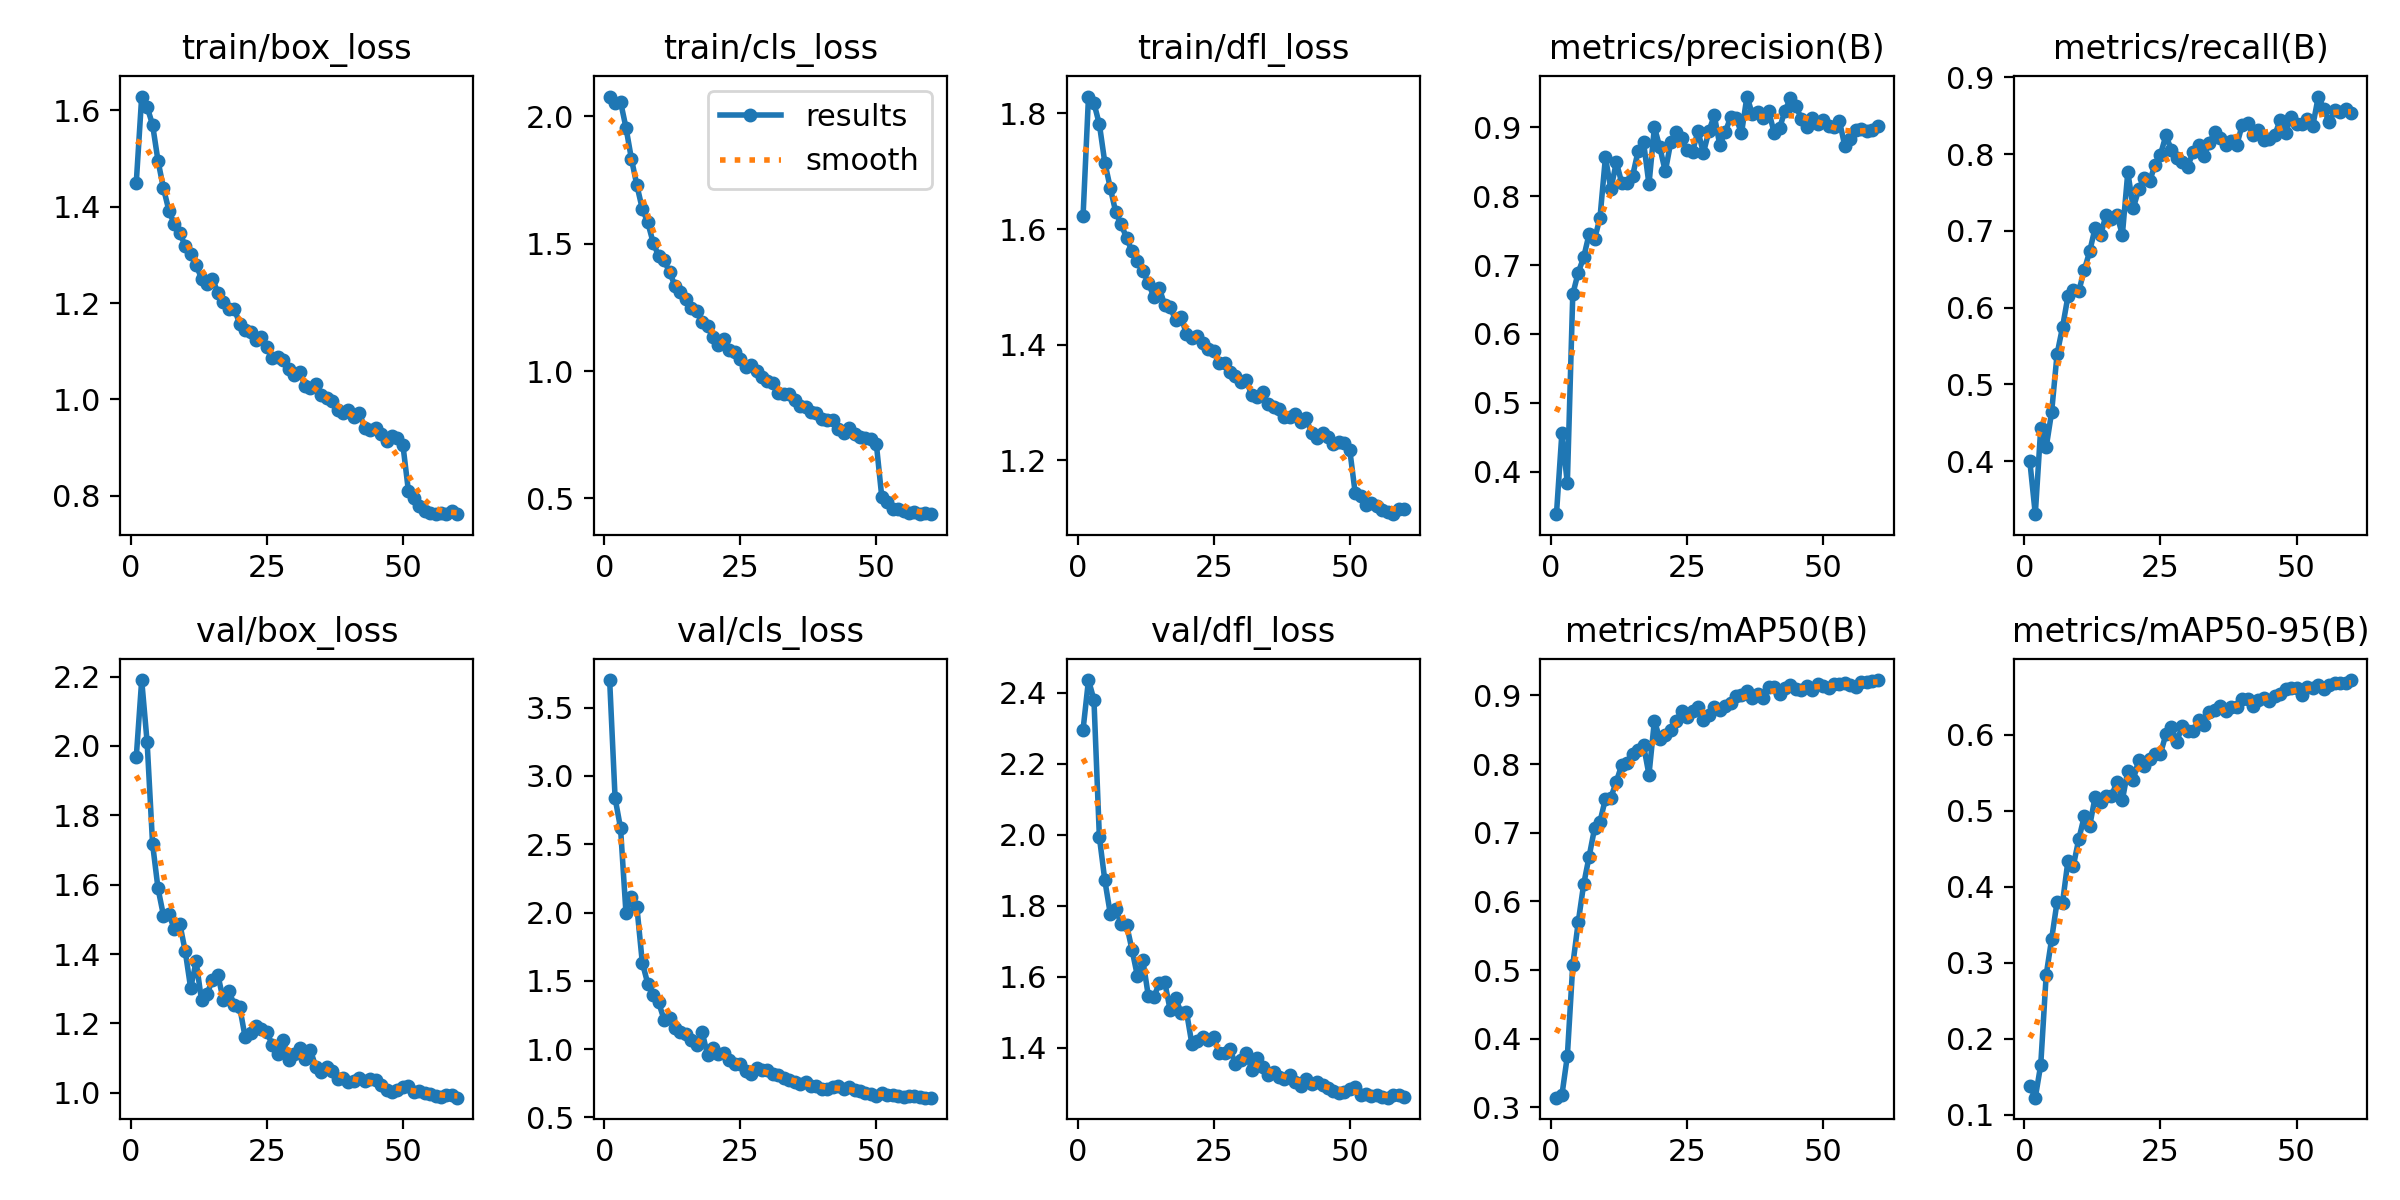

labels.jpg


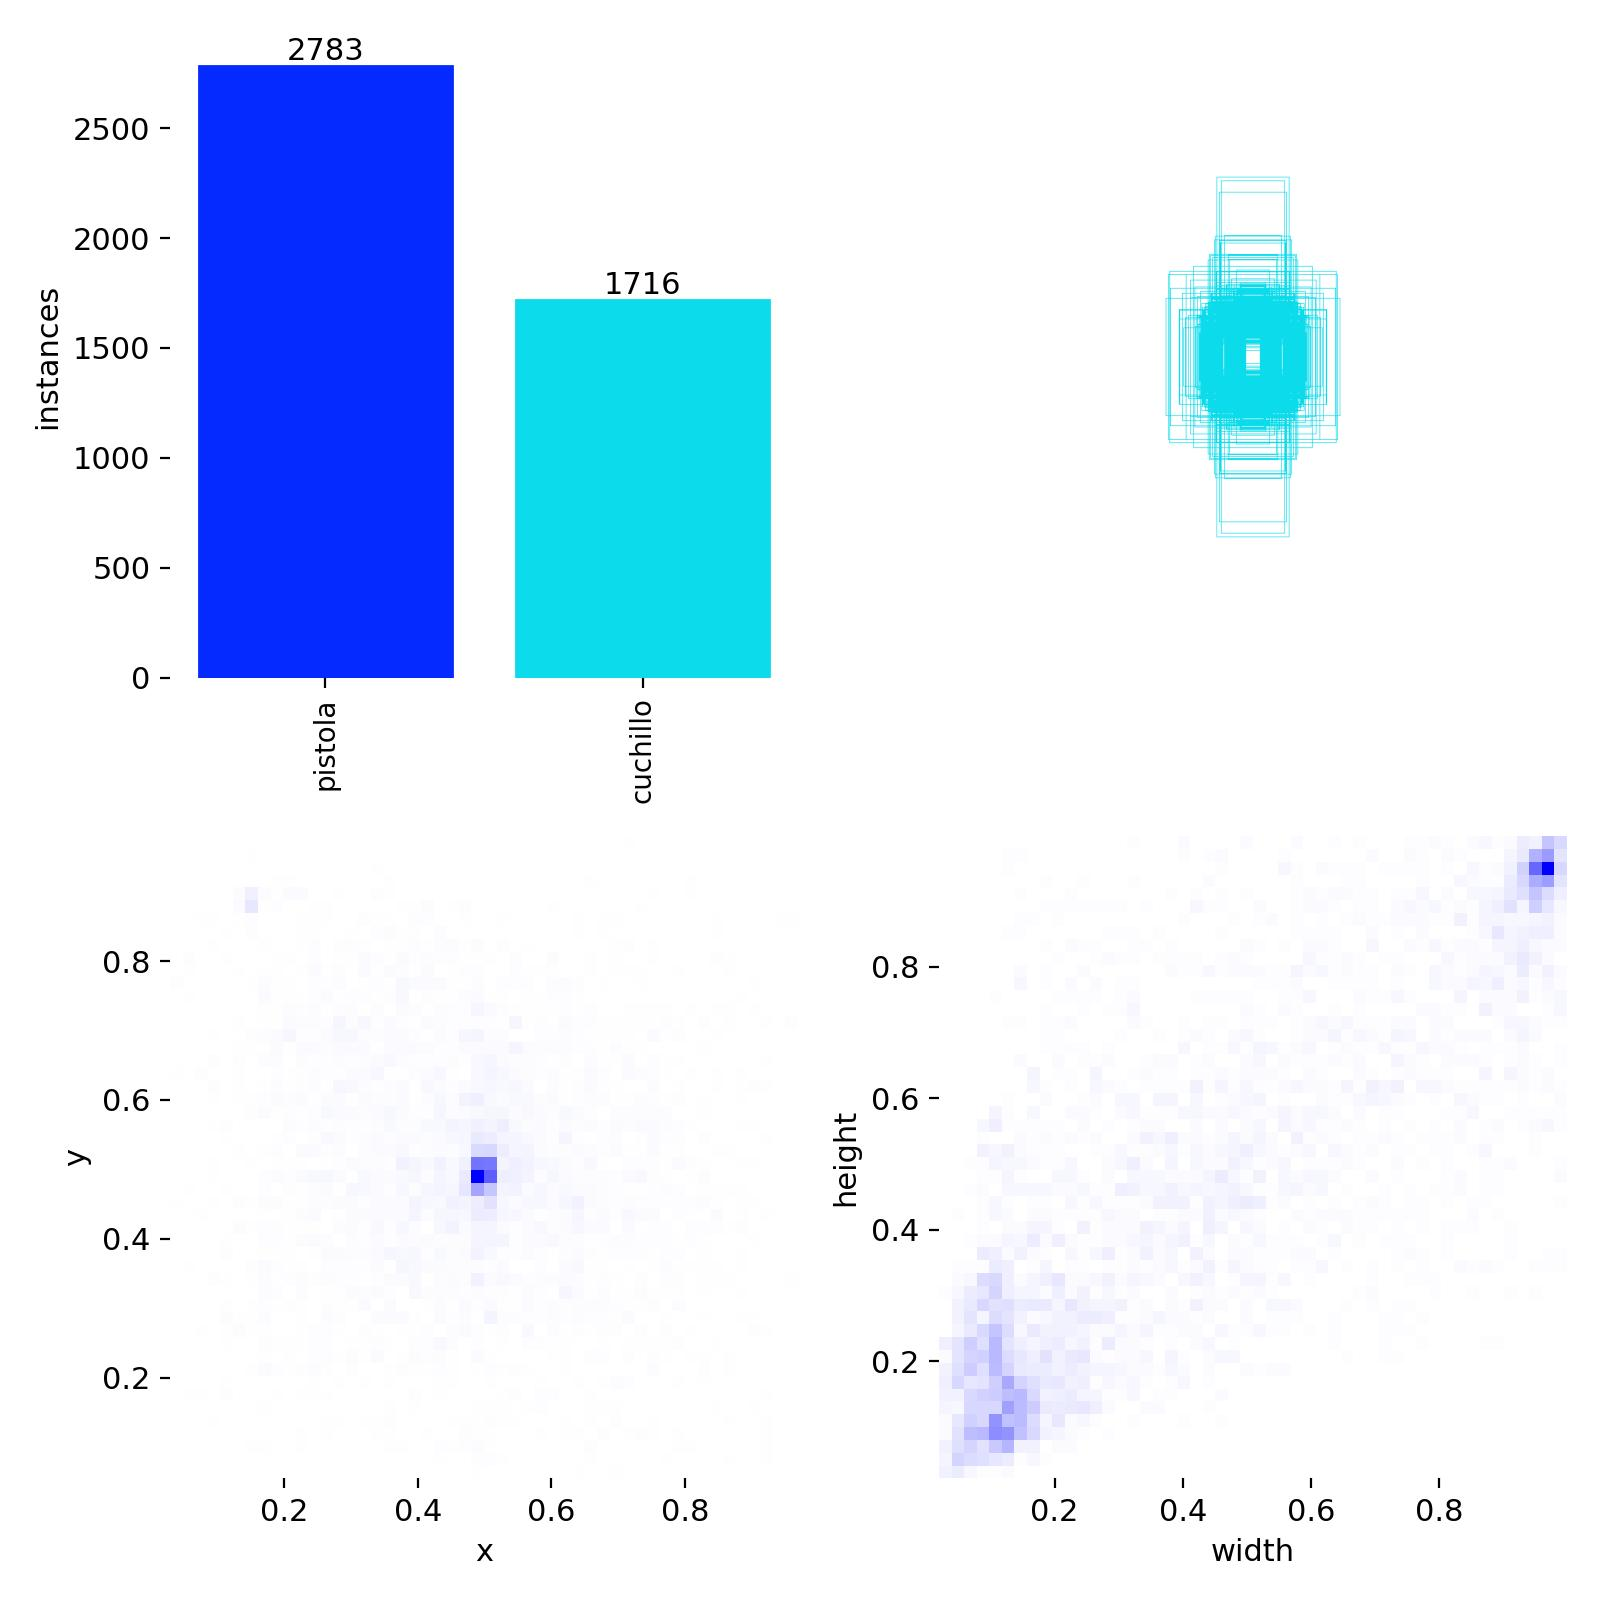

val_batch0_pred.jpg


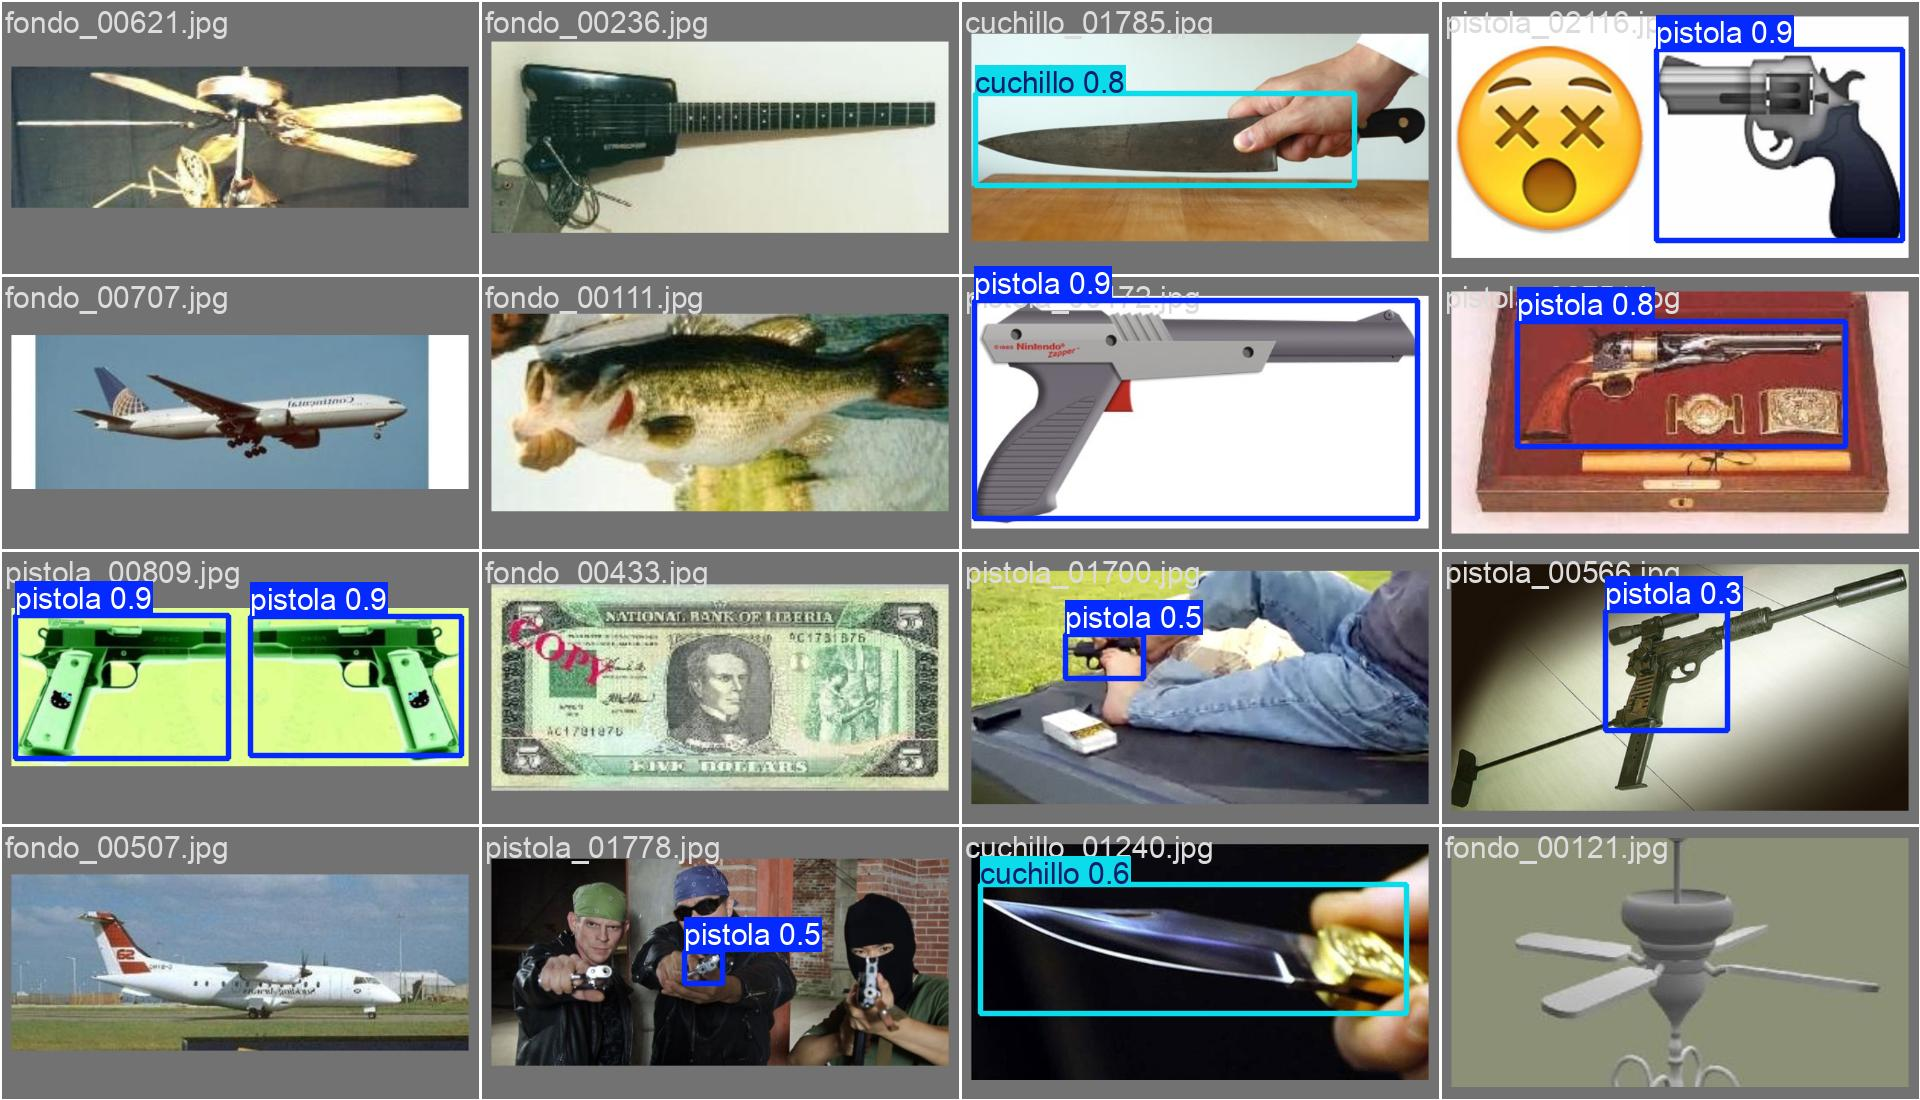

In [9]:
from IPython.display import Image as IPyImage, display

for name in ["results.png", "labels.jpg", "val_batch0_pred.jpg"]:
    f = TRAIN_DIR / name
    if f.exists():
        print(name)
        display(IPyImage(filename=str(f), width=900))

if USE_DRIVE:
    dest = DRIVE_DIR / RUN_NAME
    dest.mkdir(parents=True, exist_ok=True)
    shutil.copy(BEST_WEIGHTS, dest / "best.pt")
    shutil.copy(DATA_YAML, dest / "data.yaml")
    if (TRAIN_DIR / "results.csv").exists():
        shutil.copy(TRAIN_DIR / "results.csv", dest / "results.csv")
    print("Pesos copiados a", dest)

## 4. Evaluación con datos independientes (split *test*)

Las imágenes de test no se usaron ni para entrenar ni para elegir el mejor modelo.

**4.1 Métricas de detección (por caja):** precisión, recall, F1, mAP@0.5 y mAP@0.5:0.95 por clase.

Usando pesos: /content/runs/armas_yolo11s/weights/best.pt
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 39.4±30.1 MB/s, size: 127.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dataset/labels/test... 611 images, 102 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 611/611 447.0it/s 1.4s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 4.7it/s 8.2s
                   all        611        564      0.934      0.882      0.935      0.672
               pistola        300        344       0.92      0.838      0.897      0.707
              cuchillo        209        220  

,precisión,recall,F1,mAP@0.5,mAP@0.5:0.95
clase,,,,,
pistola,0.920,0.838,0.877,0.897,0.707
cuchillo,0.949,0.927,0.938,0.972,0.637
TODAS,0.934,0.882,0.908,0.935,0.672


Tiempo por imagen (ms): {'preprocess': 0.8, 'inference': 7.2, 'loss': 0.0, 'postprocess': 1.3}


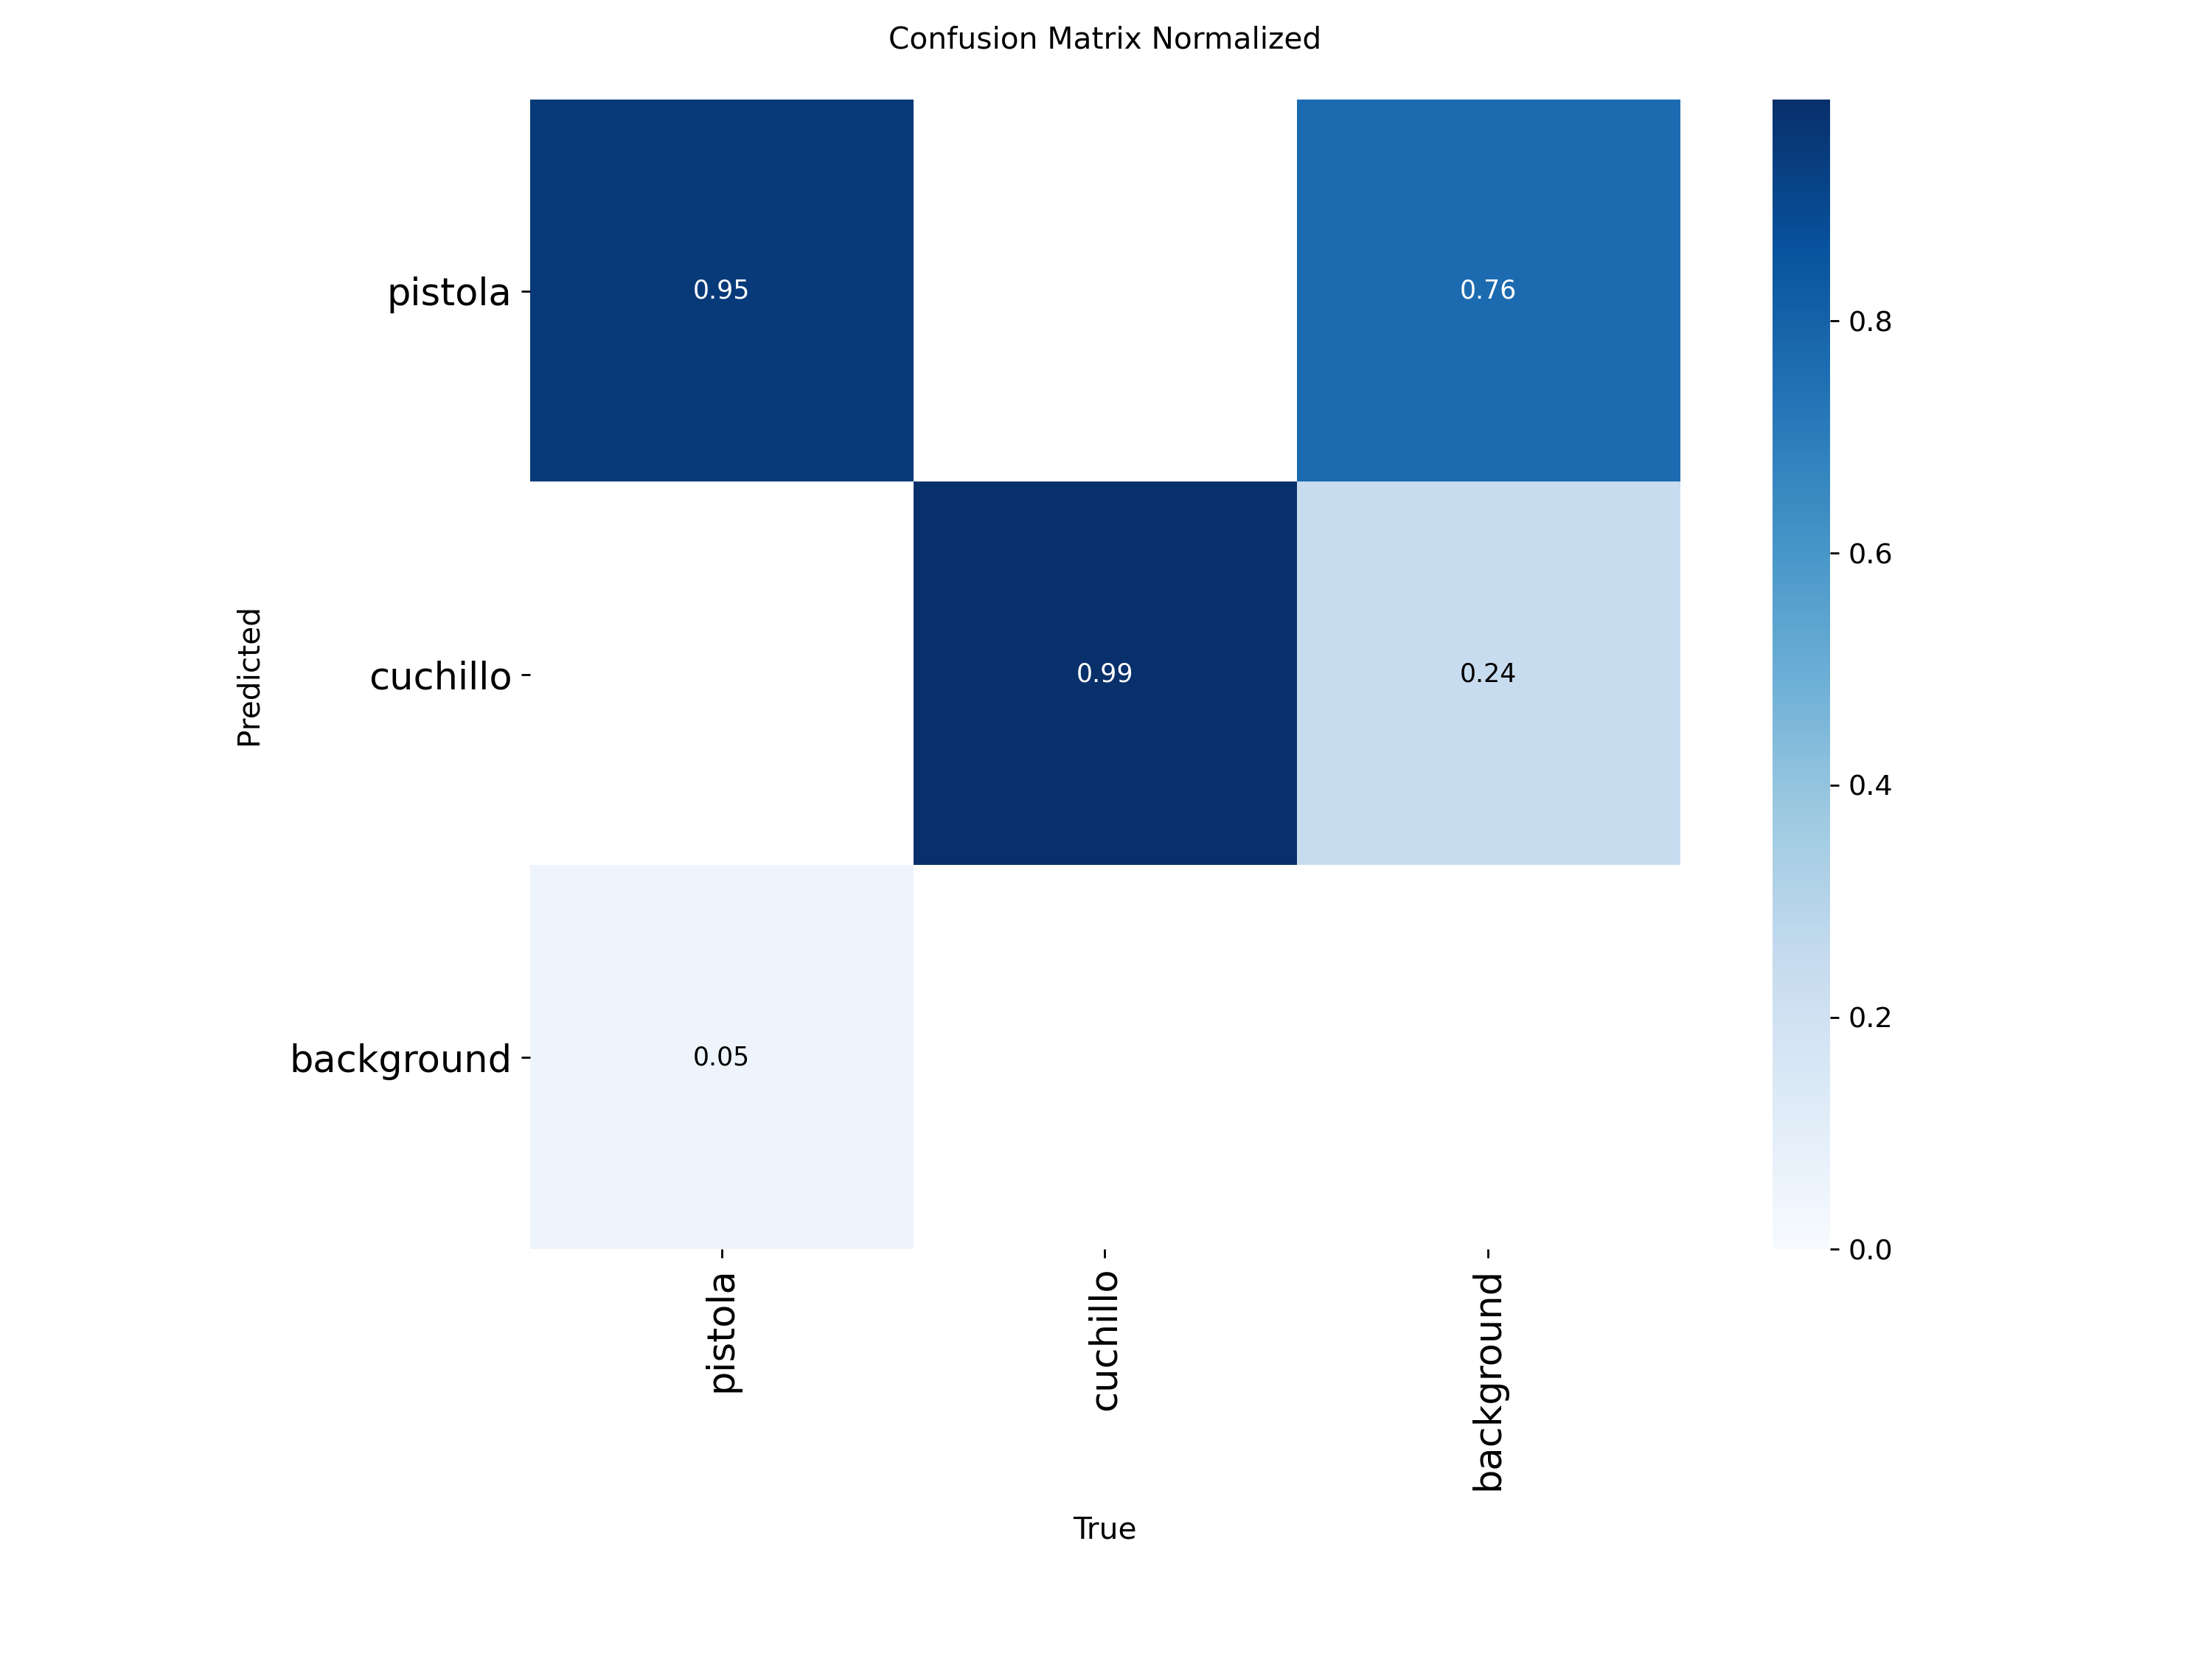

In [10]:
def resolve_weights():
    candidatos = [globals().get("BEST_WEIGHTS"),
                  RUNS_DIR / RUN_NAME / "weights" / "best.pt",
                  DRIVE_DIR / RUN_NAME / "best.pt"]
    for c in candidatos:
        if c and Path(c).exists():
            return Path(c)
    raise FileNotFoundError("No se encontraron pesos entrenados. Ejecute la sección 3 o revise Drive.")

BEST_WEIGHTS = resolve_weights()
print("Usando pesos:", BEST_WEIGHTS)
detector = YOLO(str(BEST_WEIGHTS))

test_metrics = detector.val(data=str(DATA_YAML), split="test", imgsz=IMG_SIZE, batch=BATCH,
                            project=str(RUNS_DIR), name=RUN_NAME + "_test", exist_ok=True, plots=True)

b = test_metrics.box
f1 = lambda p, r: 2 * p * r / (p + r + 1e-9)
filas = [{"clase": test_metrics.names[int(c)], "precisión": b.p[i], "recall": b.r[i],
          "F1": f1(b.p[i], b.r[i]), "mAP@0.5": b.ap50[i], "mAP@0.5:0.95": b.ap[i]}
         for i, c in enumerate(b.ap_class_index)]
filas.append({"clase": "TODAS", "precisión": b.mp, "recall": b.mr, "F1": f1(b.mp, b.mr),
              "mAP@0.5": b.map50, "mAP@0.5:0.95": b.map})
display(pd.DataFrame(filas).set_index("clase").round(3))
print("Tiempo por imagen (ms):", {k: round(v, 1) for k, v in test_metrics.speed.items()})

cm = Path(test_metrics.save_dir) / "confusion_matrix_normalized.png"
if cm.exists():
    display(IPyImage(filename=str(cm), width=600))

**4.2 Métricas a nivel de imagen ("¿hay un arma en la imagen?")**

Es la decisión que toma el servicio de alertas. Una imagen se marca como "con arma" si hay al menos una detección con confianza ≥ umbral. Se prueban varios umbrales y se elige el de mayor F1; ese valor se usa en el servicio. También se mide el tiempo total de procesamiento por imagen (lectura + preprocesamiento + inferencia + NMS).

In [11]:
import time
import numpy as np

test_imgs = sorted((DATASET_DIR / "images/test").glob("*.jpg"))
gt, max_conf, tiempos = [], [], []
detector.predict(str(test_imgs[0]), imgsz=IMG_SIZE, verbose=False)   # calentamiento de la GPU
for p in tqdm(test_imgs, desc="Inferencia test"):
    lbl = DATASET_DIR / "labels/test" / (p.stem + ".txt")
    gt.append(lbl.read_text().strip() != "")
    t0 = time.perf_counter()
    r = detector.predict(str(p), imgsz=IMG_SIZE, conf=0.05, verbose=False)[0]
    tiempos.append((time.perf_counter() - t0) * 1000)
    max_conf.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
gt, max_conf = np.array(gt), np.array(max_conf)


def image_metrics(gt, scores, thr):
    pred = scores >= thr
    tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum())
    fn = int((~pred & gt).sum()); tn = int((~pred & ~gt).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return {"umbral": round(thr, 2), "precisión": p, "recall": r, "F1": f1(p, r),
            "exactitud": (tp + tn) / len(gt), "VP": tp, "FP": fp, "FN": fn, "VN": tn}


barrido = pd.DataFrame([image_metrics(gt, max_conf, t) for t in np.arange(0.10, 0.91, 0.05)])
display(barrido.round(3).set_index("umbral"))

mejor = barrido.loc[barrido["F1"].idxmax()]
CONF_THRESHOLD = float(mejor["umbral"])
print(f"Umbral elegido (máximo F1): {CONF_THRESHOLD:.2f}")
print(f"  precisión={mejor['precisión']:.3f}  recall={mejor['recall']:.3f}  F1={mejor['F1']:.3f}")
print(f"Imágenes de test: {len(gt)} ({gt.sum()} con arma, {(~gt).sum()} sin arma)")
print(f"Tiempo de procesamiento por imagen: media {np.mean(tiempos):.1f} ms, "
      f"p95 {np.percentile(tiempos, 95):.1f} ms (≈ {1000 / np.mean(tiempos):.0f} imágenes/s)")

Inferencia test:   0%|          | 0/611 [00:00<?, ?it/s]

,precisión,recall,F1,exactitud,VP,FP,FN,VN
umbral,,,,,,,,
0.10,0.980,0.974,0.977,0.962,496,10,13,92
0.15,0.984,0.969,0.976,0.961,493,8,16,94
0.20,0.984,0.961,0.972,0.954,489,8,20,94
0.25,0.986,0.959,0.972,0.954,488,7,21,95
0.30,0.990,0.951,0.970,0.951,484,5,25,97
0.35,0.992,0.937,0.964,0.941,477,4,32,98
0.40,0.994,0.935,0.964,0.941,476,3,33,99
0.45,0.994,0.933,0.963,0.939,475,3,34,99
0.50,0.994,0.912,0.951,0.921,464,3,45,99


Umbral elegido (máximo F1): 0.10
  precisión=0.980  recall=0.974  F1=0.977
Imágenes de test: 611 (509 con arma, 102 sin arma)
Tiempo de procesamiento por imagen: media 15.7 ms, p95 24.3 ms (≈ 64 imágenes/s)


Falsos negativos: 13 | Falsos positivos: 10


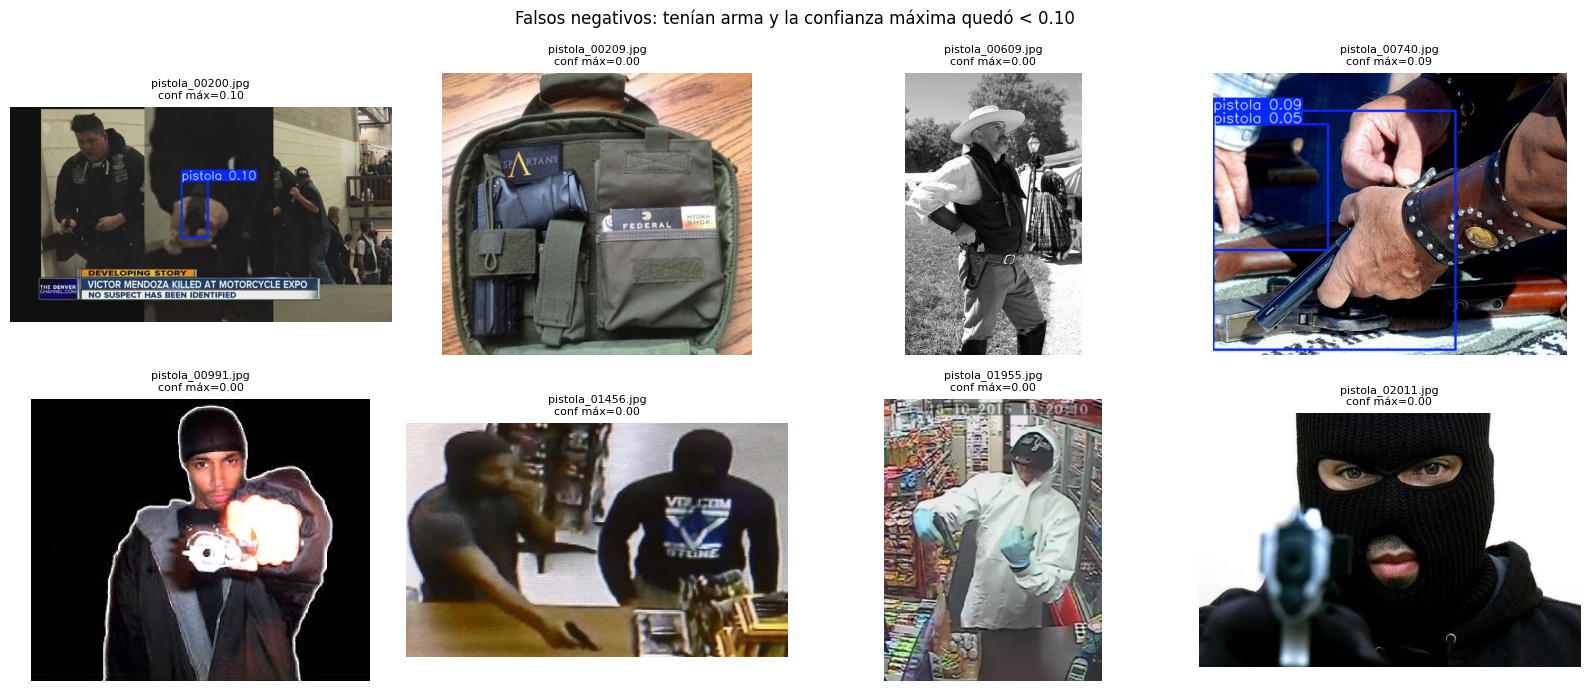

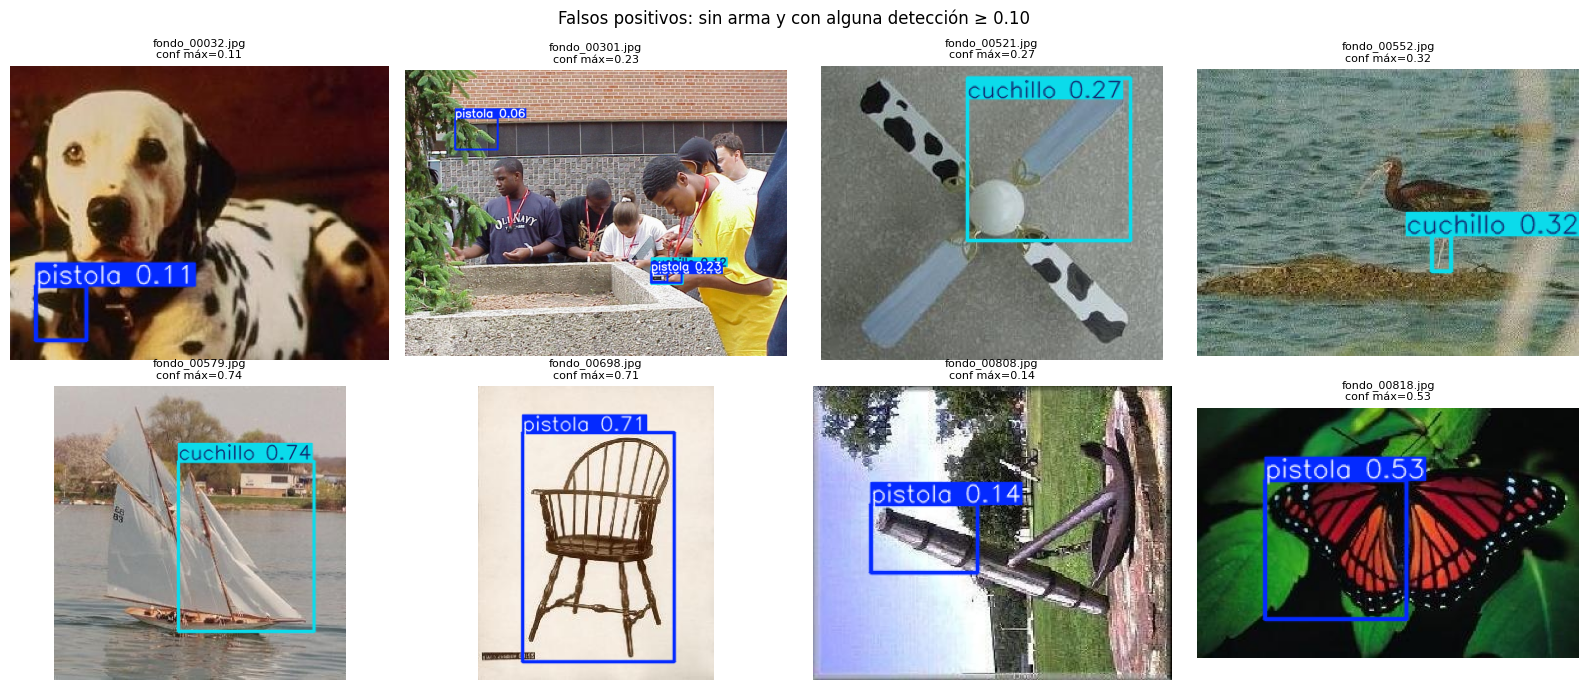

In [12]:
# Análisis de errores: falsos negativos (arma no detectada) y falsos positivos (alarma sin arma)
fn_idx = [i for i in range(len(gt)) if gt[i] and max_conf[i] < CONF_THRESHOLD]
fp_idx = [i for i in range(len(gt)) if not gt[i] and max_conf[i] >= CONF_THRESHOLD]
print(f"Falsos negativos: {len(fn_idx)} | Falsos positivos: {len(fp_idx)}")

def show_predictions(indices, titulo, n=8):
    indices = indices[:n]
    if not indices:
        print(f"{titulo}: ninguno")
        return
    cols = 4
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).flat, indices):
        r = detector.predict(str(test_imgs[i]), imgsz=IMG_SIZE, conf=0.05, verbose=False)[0]
        ax.imshow(r.plot()[:, :, ::-1])
        ax.set_title(f"{test_imgs[i].name}\nconf máx={max_conf[i]:.2f}", fontsize=8)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

show_predictions(fn_idx, f"Falsos negativos: tenían arma y la confianza máxima quedó < {CONF_THRESHOLD:.2f}")
show_predictions(fp_idx, f"Falsos positivos: sin arma y con alguna detección ≥ {CONF_THRESHOLD:.2f}")

**4.3 Prueba de robustez**

El informe reporta que la precisión cae con imágenes de baja calidad o mala iluminación. Aquí se cuantifica: se degradan las imágenes de test (oscuras, borrosas, baja resolución, ruido) y se recalculan las métricas a nivel de imagen con el umbral elegido.

In [13]:
import cv2

def oscura(img):        return np.clip(img.astype(np.float32) * 0.35, 0, 255).astype(np.uint8)
def borrosa(img):       return cv2.GaussianBlur(img, (9, 9), 0)
def baja_res(img):
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, w // 4), max(1, h // 4)), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
def ruido(img):
    n = np.random.default_rng(SEED).normal(0, 20, img.shape)
    return np.clip(img.astype(np.float32) + n, 0, 255).astype(np.uint8)

condiciones = {"original": lambda x: x, "oscura": oscura, "borrosa": borrosa,
               "baja_resolución": baja_res, "ruido": ruido}

filas = []
for nombre, fn in condiciones.items():
    scores = []
    for p in tqdm(test_imgs, desc=nombre, leave=False):
        img = fn(cv2.imread(str(p)))
        r = detector.predict(img, imgsz=IMG_SIZE, conf=0.05, verbose=False)[0]
        scores.append(float(r.boxes.conf.max()) if len(r.boxes) else 0.0)
    m = image_metrics(gt, np.array(scores), CONF_THRESHOLD)
    m["condición"] = nombre
    filas.append(m)

robustez = pd.DataFrame(filas).set_index("condición")[["precisión", "recall", "F1", "FP", "FN"]]
display(robustez.round(3))

original:   0%|          | 0/611 [00:00<?, ?it/s]

oscura:   0%|          | 0/611 [00:00<?, ?it/s]

borrosa:   0%|          | 0/611 [00:00<?, ?it/s]

baja_resolución:   0%|          | 0/611 [00:00<?, ?it/s]

ruido:   0%|          | 0/611 [00:00<?, ?it/s]

,precisión,recall,F1,FP,FN
condición,,,,,
original,0.980,0.974,0.977,10,13
oscura,0.969,0.976,0.973,16,12
borrosa,0.917,0.974,0.945,45,13
baja_resolución,0.938,0.947,0.942,32,27
ruido,0.939,0.945,0.942,31,28


## 5. Servicio de detección

Se carga el modelo entrenado, se sube una o varias imágenes y el servicio indica si hay un arma, dónde está (caja), con qué confianza y cuánto tardó.

Si el entorno se reinició y ya entrenó antes con Drive activado, basta con ejecutar la celda de configuración (sección 0), la de montaje de Drive y esta sección; los pesos se toman de Drive.

In [14]:
def detectar_armas(imagen, conf=None):
    # imagen: ruta, PIL.Image o arreglo numpy (BGR)
    conf = CONF_THRESHOLD if conf is None else conf
    t0 = time.perf_counter()
    r = detector.predict(imagen, imgsz=IMG_SIZE, conf=conf, verbose=False)[0]
    ms = (time.perf_counter() - t0) * 1000
    detecciones = [
        {"clase": r.names[int(c)], "confianza": round(float(s), 3),
         "caja_xyxy": [round(float(v), 1) for v in box]}
        for box, s, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())
    ]
    return {"hay_arma": len(detecciones) > 0, "detecciones": detecciones,
            "tiempo_ms": round(ms, 1), "imagen_anotada": r.plot()[:, :, ::-1]}


if "detector" not in globals():
    BEST_WEIGHTS = resolve_weights()
    detector = YOLO(str(BEST_WEIGHTS))
print(f"Modelo: {BEST_WEIGHTS} | umbral de confianza: {CONF_THRESHOLD:.2f}")

Modelo: /content/runs/armas_yolo11s/weights/best.pt | umbral de confianza: 0.10


Saving WhatsApp Image 2026-11-25 at 22.48.41.jpeg to WhatsApp Image 2026-11-25 at 22.48.41.jpeg


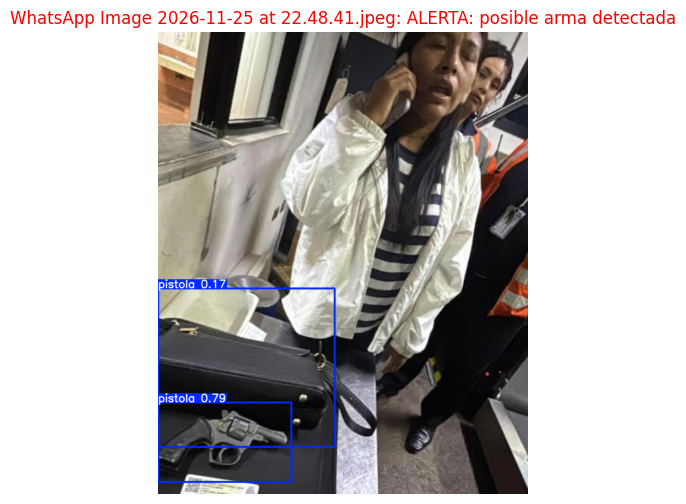

WhatsApp Image 2026-11-25 at 22.48.41.jpeg -> ALERTA: posible arma detectada (31.6 ms)
   pistola: confianza 0.79, caja [0.0, 1026.5, 369.9, 1246.4]
   pistola: confianza 0.17, caja [0.2, 710.6, 489.5, 1149.9]


In [15]:
from google.colab import files

subidas = files.upload()
for nombre in subidas:
    res = detectar_armas(nombre)
    plt.figure(figsize=(8, 6))
    plt.imshow(res["imagen_anotada"])
    plt.axis("off")
    estado = "ALERTA: posible arma detectada" if res["hay_arma"] else "Sin armas detectadas"
    plt.title(f"{nombre}: {estado}", color="red" if res["hay_arma"] else "green")
    plt.show()

    print(f"{nombre} -> {estado} ({res['tiempo_ms']} ms)")
    for d in res["detecciones"]:
        print(f"   {d['clase']}: confianza {d['confianza']:.2f}, caja {d['caja_xyxy']}")

## 6. Limitaciones y siguientes pasos

- Los negativos vienen de Caltech-101 (objetos bien encuadrados sobre fondos simples). En cámaras reales los falsos positivos pueden ser más frecuentes: teléfonos, billeteras o herramientas en la mano. El repositorio incluye `Weapons and similar handled objects / Sohas_weapon-Detection` con objetos parecidos a armas que pueden agregarse como clases o negativos difíciles.
- Las imágenes de `Pistol detection` son pequeñas (≈240 px). Armas muy pequeñas en escenas amplias (cámaras de vigilancia) requieren imágenes de entrenamiento de ese tipo y quizá `IMG_SIZE = 960`.
- Para video en tiempo real: `detector.predict(source="video.mp4", stream=True, conf=CONF_THRESHOLD)` o exportar a ONNX/TensorRT con `detector.export(format="onnx")`.